# 01 Sizing non-payment

Put the different non-payment measures side by side. They measure different things, so do not force them into one number.

In [9]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parents[2]      # repo root, two levels above this folder
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.common.config import load_config
from src.common.pipeline import build

cfg = load_config()
MODE = os.environ.get("DATA_MODE")          # None = use config; "synthetic" = fake
ghs, ies, nfcm = build(MODE, save=False)

C:\Users\mmjmo\Projects\sa-electricity-nonpayment\src\common\pipeline.py:28: UnicodeWarning: 
One or more strings in the dta file could not be decoded using utf-8, and
so the fallback encoding of latin-1 is being used.  This can happen when a file
has been incorrectly encoded by Stata or some other software. You should verify
the string values returned are correct.
  return pd.read_stata(full, convert_categoricals=False)


In [10]:
from src.a_who_pays import sizing

measures = sizing.load_measures(ROOT / "data" / "processed" / "nonpayment_measures.csv")
measures

,measure,date,value,unit,source,verified
0,eskom_revenue_not_recognised_collection_risk,2026-03-31,15.80,rand_bn,Ministerial reply NW4902 (net amount; about 4....,False
1,ghs_households_not_paying_electricity,2025-12-31,2668635.00,households,Own weighted calculation: GHS 2025 household f...,True
2,ghs_share_not_paying_among_yes_no,2025-12-31,14.67,percent,Own weighted calculation: GHS 2025 eng_pay; 2....,True
3,municipal_debt_programme_participants,2025-12-31,85.20,rand_bn,National Treasury 2026 Budget Review (71 parti...,True
4,municipal_debt_to_eskom_total,2025-03-31,94.60,rand_bn,Engineering News Mar 2026 (confirm in Eskom re...,False
5,municipal_debt_to_eskom_total,2026-03-31,111.60,rand_bn,Eskom FY2026 results as reported by Daily Inve...,False
6,municipal_debt_to_eskom_total,2026-07-31,120.26,rand_bn,Ministerial reply NW4902 (pmg.org.za/committee...,False
7,nfcm_free_basic_electricity_households,2023-06-30,1849746.00,households,Stats SA NFCM time series 2006-2023 (2023 valu...,True
8,nfcm_indigent_beneficiaries_electricity,2023-06-30,1721812.00,households,Stats SA NFCM time series 2006-2023 (2023 valu...,True
9,nfcm_indigent_households_identified,2023-06-30,2757643.00,households,Stats SA NFCM time series 2006-2023 (2023 valu...,True


Anything with `verified = False` must be checked against a primary source before it is used in the paper.

In [11]:
latest = sizing.latest_by_measure(measures)
latest

,measure,date,value,unit,source,verified
0,nfcm_free_basic_electricity_households,2023-06-30,1849746.00,households,Stats SA NFCM time series 2006-2023 (2023 valu...,True
1,nfcm_indigent_beneficiaries_electricity,2023-06-30,1721812.00,households,Stats SA NFCM time series 2006-2023 (2023 valu...,True
2,nfcm_indigent_households_identified,2023-06-30,2757643.00,households,Stats SA NFCM time series 2006-2023 (2023 valu...,True
3,ghs_households_not_paying_electricity,2025-12-31,2668635.00,households,Own weighted calculation: GHS 2025 household f...,True
4,ghs_share_not_paying_among_yes_no,2025-12-31,14.67,percent,Own weighted calculation: GHS 2025 eng_pay; 2....,True
5,municipal_debt_programme_participants,2025-12-31,85.20,rand_bn,National Treasury 2026 Budget Review (71 parti...,True
6,eskom_revenue_not_recognised_collection_risk,2026-03-31,15.80,rand_bn,Ministerial reply NW4902 (net amount; about 4....,False
7,municipal_debt_to_eskom_total,2026-07-31,120.26,rand_bn,Ministerial reply NW4902 (pmg.org.za/committee...,False


# Why can't we add these measures together?
They count different things in different units. Municipal debt and revenue not recognised are
rand (one a stock owed, the other a loss in a single year). The survey and the indigent figures
count households. They also overlap: a municipal customer's unpaid bill can appear in both
municipal debt and Eskom's revenue not recognised, so adding them would count it twice.
Indigent households are registered as unable to pay, which is a policy status and not the same
as not paying.

# Why does R85.2bn differ from R120.26bn?
R85.2bn is what the 71 municipalities in the debt relief programme owed Eskom in December 2025
(Budget Review). R120.26bn is total overdue municipal debt to Eskom at 31 July 2026. The gap most
likely reflects coverage (programme participants against all municipalities) and date (seven months
later, while debt keeps growing).

# Which measure best fits "how many households don't pay"?
The GHS 2025 figure: about 2.67 million households say they do not pay for electricity, 14.7% of
those answering yes or no. It counts households, and its weights match the published household
totals. Its limits: it is self-reported, and it may include households whose electricity is free,
included in rent or supplied through a neighbour. About 1.7 million prepaid households also answered
"No", which needs explaining.

In [12]:
growth = sizing.annual_growth(measures, "municipal_debt_to_eskom")
print(f"Municipal debt to Eskom, compound annual growth: {growth:.1%}")

Municipal debt to Eskom, compound annual growth: nan%


# What does 19.7% a year mean?
Municipal debt to Eskom grew by about 19.7% a year, compounded, between March 2025 (R94.6bn) and
July 2026 (R120.26bn). That is about R25.7bn over 16 months, or roughly R19bn a year. Caution: this
uses only three points, two of them from press reports, over a short period. Debt also grows from
interest and penalties, so the growth in the debt is not the same as new non-payment in the year.

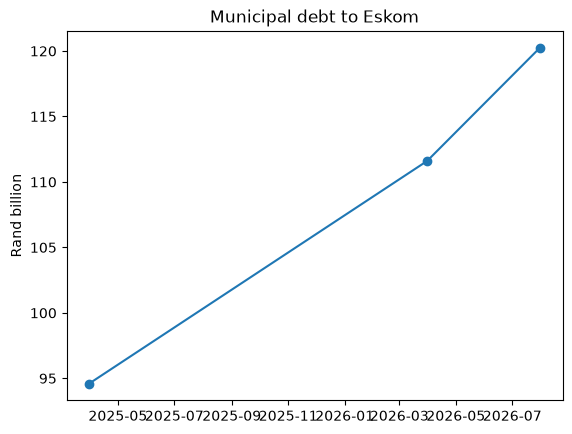

In [13]:
%matplotlib inline
debt = measures[measures["measure"] == "municipal_debt_to_eskom_total"]
assert len(debt) > 1, "No debt rows found: check the measure name in nonpayment_measures.csv"
plt.plot(debt["date"], debt["value"], marker="o")
plt.ylabel("Rand billion")
plt.title("Municipal debt to Eskom")
plt.show()

# Limits
- Two of the debt figures and the R15.8bn are not yet verified against a primary source.
- The measures come from different dates and publishers, so they cannot be compared one-to-one.
- A survey can only show what households report, not what Eskom or municipalities record.